# Emotional vs neutral: matched by node and calendar date

**Question:** when E and N are compared on the same machine and date, how large is the difference—and does it persist across nodes and dates?

This notebook uses all compatible **70B E/N fulltrace batches**, with three PTE features: **mean throttle rate, spectral entropy, and PTE/cycles**. It first averages recordings within each condition × node × date, then compares those averages. One matched node/date is one comparison.

Positive differences mean **E > N numerically**. Original recordings, feature CSVs, and earlier notebooks are preserved.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
from fulltrace_matched import prepare, analyze, display_effect, SPECS as ALL_SPECS

SELECTED_FEATURES = {"core_power.throttle__mean_rate",
                     "core_power.throttle__spectral_entropy",
                     "core_power.throttle__per_cycle"}
SPECS = [s for s in ALL_SPECS if s[0] in SELECTED_FEATURES]

TIMEZONE = "America/Chicago"
TEST_BOOTSTRAPS = 19999
INTERVAL_BOOTSTRAPS = 1999
SEED = 42
WORKERS = 4  # Use 1 for a single process.
OUT = ROOT / "results/fulltrace_matched_EN_2026-10-23_three_features"
OUT.mkdir(parents=True, exist_ok=True)
E_COLOR, N_COLOR = "#C44E52", "#4477AA"
FEATURES = [s[0] for s in SPECS]
LABELS = {s[0]: s[1] for s in SPECS}
UNITS = {s[0]: s[3] for s in SPECS}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Each row below will be a matched comparison, not an individual timestamp.")

Each row below will be a matched comparison, not an individual timestamp.


## 1. Match the recordings

Dates come from raw start timestamps in America/Chicago. **Midnight-crossing traces use their earlier/start date.** Node IDs are taken from folder labels, assuming they identify the same physical node across reservations.

Only successful 70B E/N recordings with matching recomputed feature files are eligible. Aggregate CSVs, joy, and mechanical recordings are excluded. Collection settings are checked before pooling. A node/date lacking either condition is reported and excluded from matching.

,count
quantity,
Recordings,70
Matched node/date groups,23
Nodes,17
Dates,7
One E + one N,11
Two E + two N,12
Cross-midnight recordings,5


condition,emotional,neutral
batch,,
batch_001_en,20,20
batch_003_enj,10,10
batch_004_enm,5,5


Excluded other conditions/models: 35; unmatched groups: 0


,day,node,batch,n_E,n_N
0,2026-05-04,244,batch_001_en,2,2
1,2026-05-04,249,batch_001_en,1,1
2,2026-05-06,230,batch_001_en,2,2
3,2026-05-07,226,batch_001_en,1,1
4,2026-05-10,222,batch_001_en,2,2
5,2026-05-10,224,batch_001_en,2,2
6,2026-05-10,229,batch_001_en,2,2
7,2026-05-10,246,batch_001_en,2,2
8,2026-05-10,252,batch_001_en,2,2
9,2026-05-12,231,batch_001_en,1,1


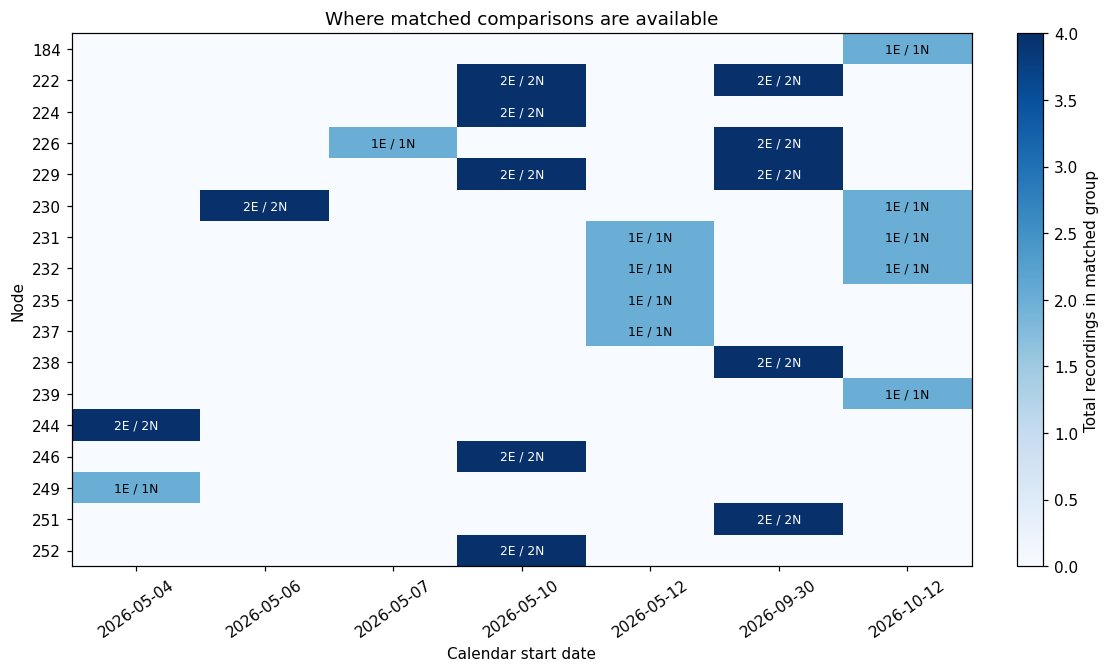

In [2]:
traces, blocks, contrasts, sources, excluded, unmatched = prepare(ROOT, TIMEZONE, features=FEATURES)
coverage = pd.DataFrame({"quantity": ["Recordings", "Matched node/date groups", "Nodes", "Dates",
                                   "One E + one N", "Two E + two N", "Cross-midnight recordings"],
                         "count": [len(traces), len(blocks), blocks.node.nunique(), blocks.day.nunique(),
                                   int(((blocks.n_E == 1) & (blocks.n_N == 1)).sum()),
                                   int(((blocks.n_E == 2) & (blocks.n_N == 2)).sum()),
                                   int(traces.crosses_midnight.sum())]})
display(coverage.set_index("quantity"))
display(pd.crosstab(traces.batch, traces.condition))
print(f"Excluded other conditions/models: {len(excluded)}; unmatched groups: {len(unmatched)}")
if len(unmatched): display(unmatched)
display(blocks[["day", "node", "batch", "n_E", "n_N"]])
for name, table in [("input_recordings", traces), ("matched_groups", blocks),
                    ("matched_contrasts", contrasts), ("input_checksums", sources),
                    ("excluded_recordings", excluded), ("unmatched_groups", unmatched)]:
    table.to_csv(OUT / f"{name}.csv", index=False)

nodes = sorted(blocks.node.unique(), key=int)
dates = sorted(blocks.day.unique())
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
values = np.zeros((len(nodes), len(dates)))
for row in blocks.itertuples(index=False):
    i, j = nodes.index(row.node), dates.index(row.day)
    values[i, j] = row.n_E + row.n_N
im = ax.imshow(values, cmap="Blues", vmin=0, vmax=max(4, values.max()), aspect="auto")
for row in blocks.itertuples(index=False):
    ax.text(dates.index(row.day), nodes.index(row.node), f"{row.n_E}E / {row.n_N}N",
            ha="center", va="center", fontsize=8,
            color="white" if row.n_E + row.n_N >= 4 else "black")
ax.set(xticks=range(len(dates)), xticklabels=dates, yticks=range(len(nodes)), yticklabels=nodes,
       xlabel="Calendar start date", ylabel="Node", title="Where matched comparisons are available")
ax.tick_params(axis="x", rotation=35)
fig.colorbar(im, ax=ax, label="Total recordings in matched group")
save_figure(fig, "coverage")

## 2. Compare E and N inside each group

For each feature, average **recording-level values** separately for E and N within the same node/date. PTE/cycles is calculated per recording before averaging.

- **Absolute difference:** E average − N average.
- **Percentage difference:** 100 × (E average − N average) / N average, when a positive baseline makes that meaningful.

The model uses **log(E average / N average)** for mean rate and PTE/cycles; estimates are converted back to percentages. This is the log of the ratio of arithmetic cell means, not the difference of average log-recordings. Spectral entropy uses absolute differences.

Each connecting line below is one node/date group. The next plot removes the shared baseline and shows just its E−N difference. Single-recording groups receive no individual confidence interval or significance test.

**Worked example from your data: 2026-05-04 / 244**

,E_mean,N_mean,raw_difference,effect,unit
label,,,,,
Mean throttle rate,1.1567e+09,1.084e+09,7.272e+07,6.7088,% vs neutral
Spectral entropy,0.91745,0.91203,0.0054178,0.0054178,entropy units
PTE / cycles,0.0089799,0.0083581,0.00062182,7.4397,% vs neutral


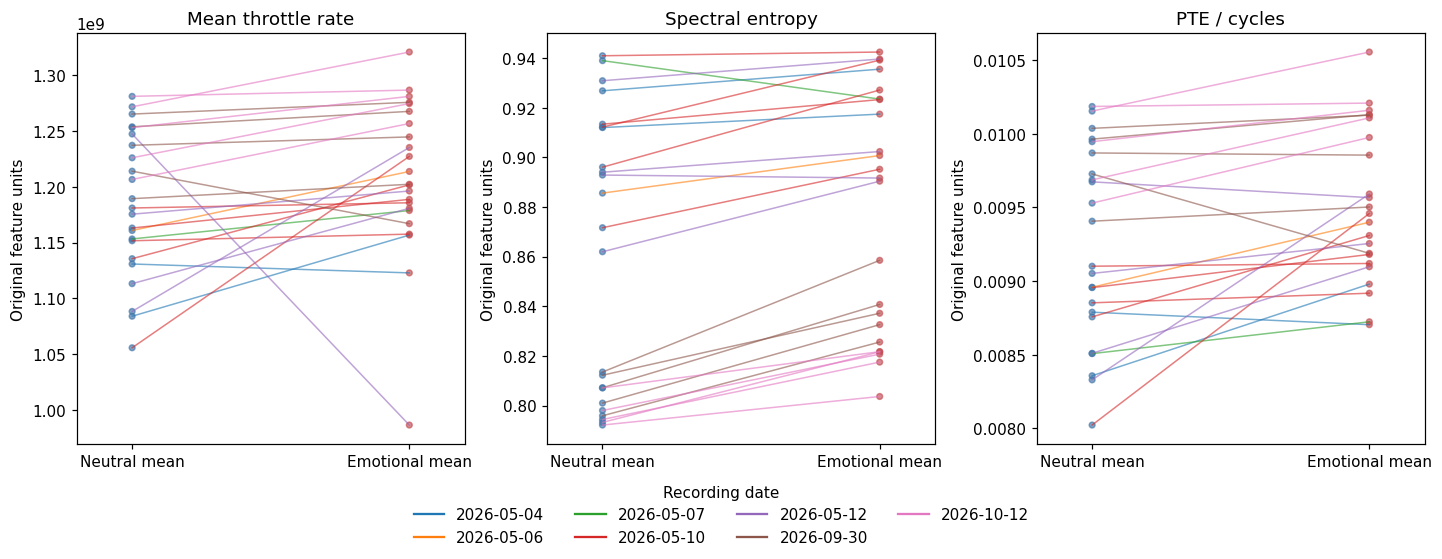

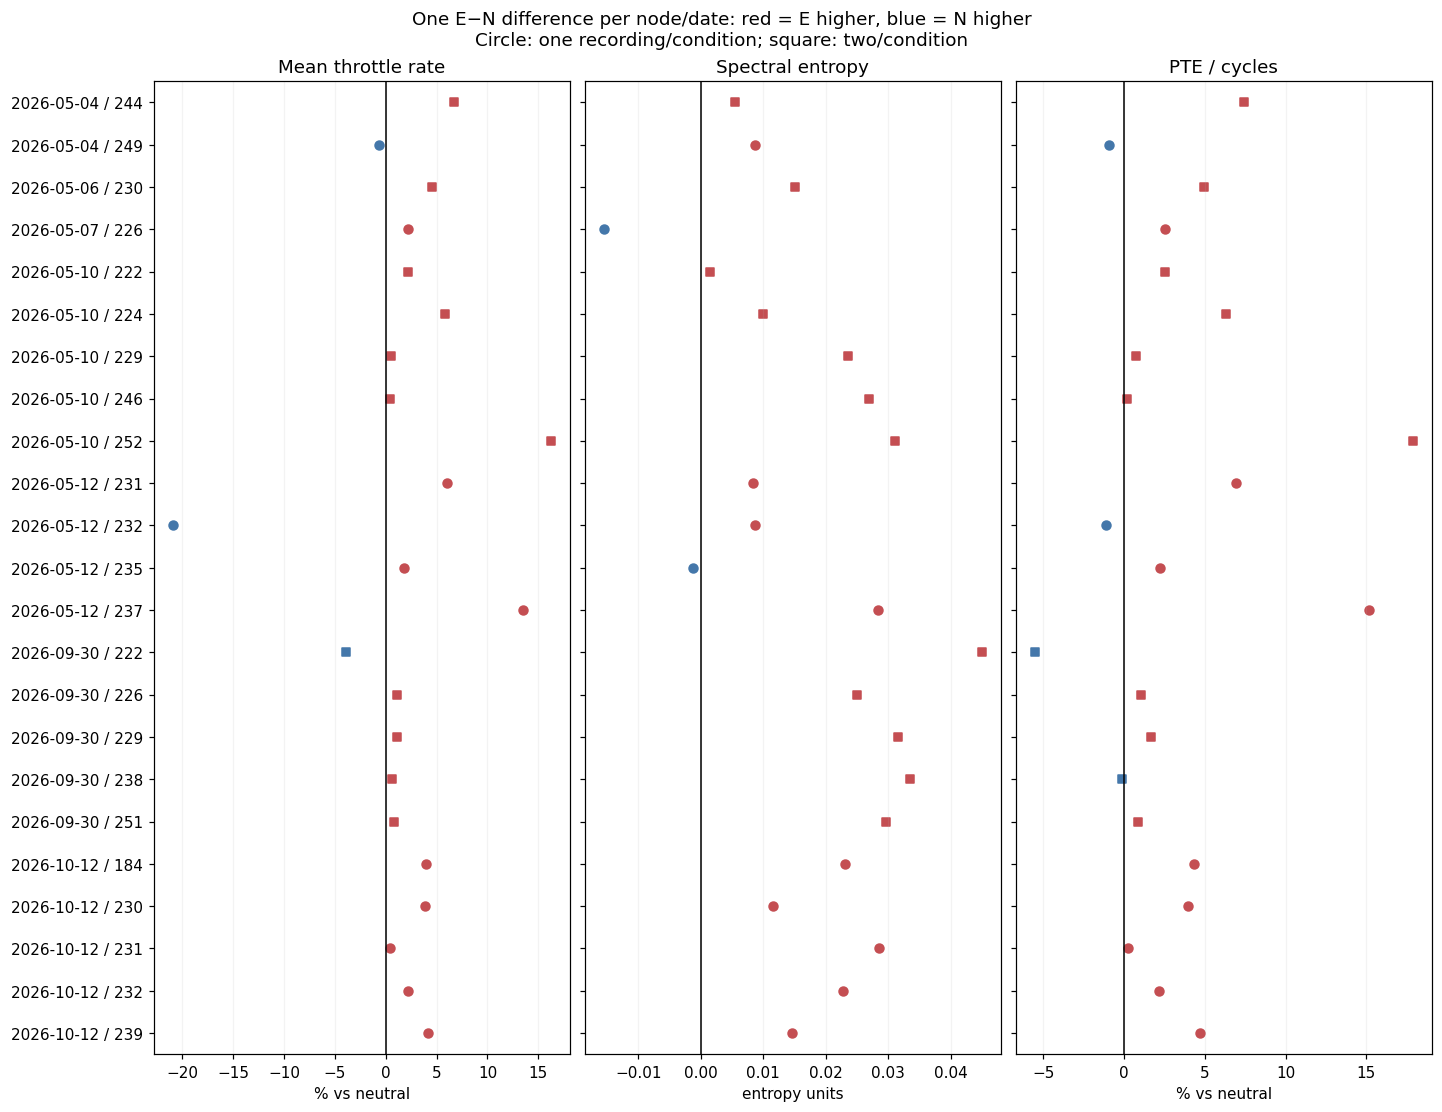

In [3]:
example = contrasts.loc[contrasts.block == blocks.block.iloc[0],
    ["label", "E_mean", "N_mean", "raw_difference", "effect", "unit"]]
display(Markdown(f"**Worked example from your data: {blocks.block.iloc[0]}**"))
with pd.option_context("display.float_format", "{:.5g}".format):
    display(example.set_index("label"))

date_colors = dict(zip(dates, plt.get_cmap("tab10").colors[:len(dates)]))
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 5), layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes.flat, SPECS):
    sub = contrasts.loc[contrasts.feature == feature]
    for row in sub.itertuples(index=False):
        ax.plot([0, 1], [row.N_mean, row.E_mean], color=date_colors[row.day], alpha=.6, linewidth=1)
        ax.scatter([0, 1], [row.N_mean, row.E_mean], color=[N_COLOR, E_COLOR], s=14, alpha=.65)
    ax.set(xticks=[0, 1], xticklabels=["Neutral mean", "Emotional mean"], title=label,
           ylabel="Original feature units", xlim=(-.2, 1.2))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 4))
fig.legend([plt.Line2D([0], [0], color=date_colors[d]) for d in dates], dates,
                     title="Recording date", loc="outside lower center", ncol=4, frameon=False)
save_figure(fig, "paired_means")

fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 10), sharey=True, layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes, SPECS):
    sub = contrasts.loc[contrasts.feature == feature].set_index("block").loc[blocks.block]
    for i, row in enumerate(sub.itertuples()):
        ax.scatter(row.effect, i, color=E_COLOR if row.effect > 0 else N_COLOR,
                   marker="o" if row.n_E == row.n_N == 1 else "s", s=34)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=label, xlabel=unit, yticks=range(len(blocks)), yticklabels=blocks.block)
    ax.set_ylim(len(blocks)-.5, -.5)
    ax.grid(axis="x", alpha=.15)
fig.suptitle("One E−N difference per node/date: red = E higher, blue = N higher\nCircle: one recording/condition; square: two/condition", fontsize=12)
save_figure(fig, "matched_differences")

## 3. Estimate the overall difference—and its uncertainty

A positive mean difference can coexist with reversals on some nodes/dates. We ask both **“is there an overall association?”** and **“how variable is that association?”**

Fit the following model to the 23 matched contrasts (not to 70 independent traces):

> E−N contrast = overall contrast + node-related contrast variation + date-related contrast variation + remaining variation

Node/date terms now describe **variation in the E−N gap**, not variation in raw baselines. Crossed groups account for repeated nodes and shared dates. The overall estimate accounts for correlation and is not a simple arithmetic average of the displayed percentages. Each group contributes one contrast; groups with extra trace repetitions are not counted as extra independent groups. The residual variance is assumed common across contrasts, despite differing repeat counts; with only one or two traces/condition, separate group precisions cannot be reliably estimated. Remaining variance mixes measurement noise and unexplained node×date variation.

**Overall test:** compare the fitted model against one whose overall contrast is zero, retaining node/date variation in both. Parametric-bootstrap likelihood-ratio tests simulate this zero-effect model and refit both models from multiple starting values. Holm correction covers the **three** overall feature tests.

The 95% interval for the **overall effect** uses a studentized parametric bootstrap. An approximate **prediction interval** includes uncertainty and heterogeneity for a future matched comparison on a **new node and new date**, under comparable collection settings and recording design. It is a model-based estimate, not demonstrated performance on new data. Intervals are pointwise; they are not multiplicity-adjusted.

The model assumes independent Gaussian node/date contributions and remaining errors on the contrast scale. With seven dates, sparse overlap, and possible outliers, all inference is exploratory. Details are in `analysis/lib/fulltrace_matched.py`.

References: [crossed mixed models](https://www.statsmodels.org/stable/mixed_linear.html), [parametric bootstrap](https://lme4.github.io/lme4/reference/bootMer.html), [studentized intervals](https://stat.ethz.ch/R-manual/R-devel/library/boot/html/boot.ci.html).

**Selection note:** these three features were selected after viewing the earlier five-feature results. The three-test correction is exploratory; the original five-test inference is preserved separately.

In [4]:
estimates, sensitivity, residuals, bootstrap_means = analyze(
    contrasts, test_repeats=TEST_BOOTSTRAPS, interval_repeats=INTERVAL_BOOTSTRAPS,
    seed=SEED, workers=WORKERS,
)
for name, table in [("overall_effects", estimates), ("leave_one_group_out", sensitivity),
                    ("model_residuals", residuals), ("bootstrap_means", bootstrap_means)]:
    table.to_csv(OUT / f"{name}.csv", index=False)
configuration = dict(timezone=TIMEZONE, date_rule="trace start date", seed=SEED,
                     test_bootstraps=TEST_BOOTSTRAPS, interval_bootstraps=INTERVAL_BOOTSTRAPS,
                     workers=WORKERS, features=FEATURES, n_traces=len(traces), n_groups=len(blocks),
                     correction="Holm over three overall E-N tests", estimation="Gaussian ML",
                     interval="studentized parametric bootstrap; pointwise 95%",
                     prediction="approximate bootstrap mixture for new node and new date")
(OUT / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")

report = pd.DataFrame({"Feature": estimates.label, "Units": estimates.unit,
    "Overall E−N": estimates.display_estimate,
    "95% CI lower": estimates.display_ci_low, "95% CI upper": estimates.display_ci_high,
    "New-group range lower": estimates.display_prediction_low,
    "New-group range upper": estimates.display_prediction_high,
    "Holm p": estimates.p_holm,
    "E > N groups": [f"{p}/{len(blocks)}" for p in estimates.n_positive],
    "MC-sensitive": estimates.mc_sensitive})
display(report.round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)
print("A confidence interval excluding zero and a Holm test answer different questions: intervals are pointwise.")
if estimates.mc_sensitive.any():
    display(estimates.loc[estimates.mc_sensitive, ["label", "p_holm", "p_holm_mc_low", "p_holm_mc_high"]])

,Feature,Units,Overall E−N,95% CI lower,95% CI upper,New-group range lower,New-group range upper,Holm p,E > N groups,MC-sensitive
0,Mean throttle rate,% vs neutral,2.0702,-0.7208,4.8873,-10.8445,16.7649,0.1312,20/23,False
1,Spectral entropy,entropy units,0.0146,0.0025,0.0273,-0.0153,0.0447,0.0866,21/23,False
2,PTE / cycles,% vs neutral,3.6155,1.0094,6.2040,-5.7617,14.0698,0.0382,19/23,False


A confidence interval excluding zero and a Holm test answer different questions: intervals are pointwise.


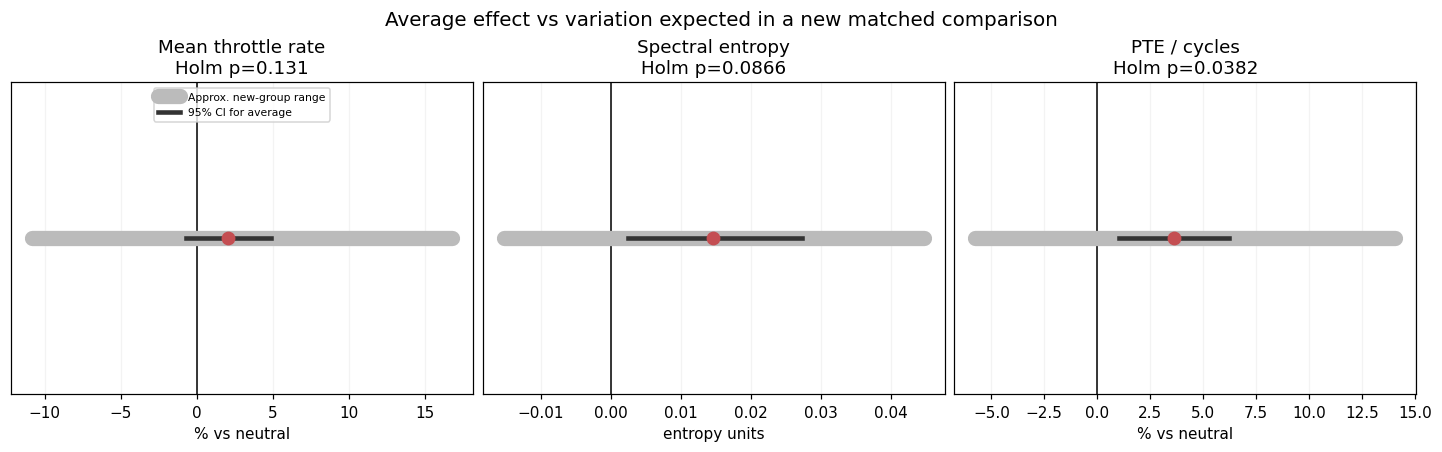

In [5]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4), layout="constrained")
for ax, row in zip(axes, estimates.itertuples(index=False)):
    ax.axvline(0, color="black", linewidth=1)
    ax.plot([row.display_prediction_low, row.display_prediction_high], [0, 0],
            color="#BBBBBB", linewidth=10, solid_capstyle="round", label="Approx. new-group range")
    ax.plot([row.display_ci_low, row.display_ci_high], [0, 0], color="#333333", linewidth=3,
            label="95% CI for average")
    ax.scatter(row.display_estimate, 0, s=65, zorder=5,
               color=E_COLOR if row.display_estimate > 0 else N_COLOR)
    ax.set(title=f"{row.label}\nHolm p={row.p_holm:.3g}", xlabel=row.unit, yticks=[], ylim=(-1, 1))
    ax.grid(axis="x", alpha=.15)
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Average effect vs variation expected in a new matched comparison", fontsize=13)
save_figure(fig, "overall_effects")

## 4. Does the direction hold across dates and nodes?

Small colored dots below are the original matched comparisons. Diamonds summarize comparisons **on the model scale** within a date or node, then convert to display units. For percentages, that is a geometric summary of E/N ratios. These are descriptive summaries; groups sharing a date/node are related.

Look for agreement in direction and effect size. Several positive dots from one date do not count as several independent dates. A stable overall average alone does not establish consistency.

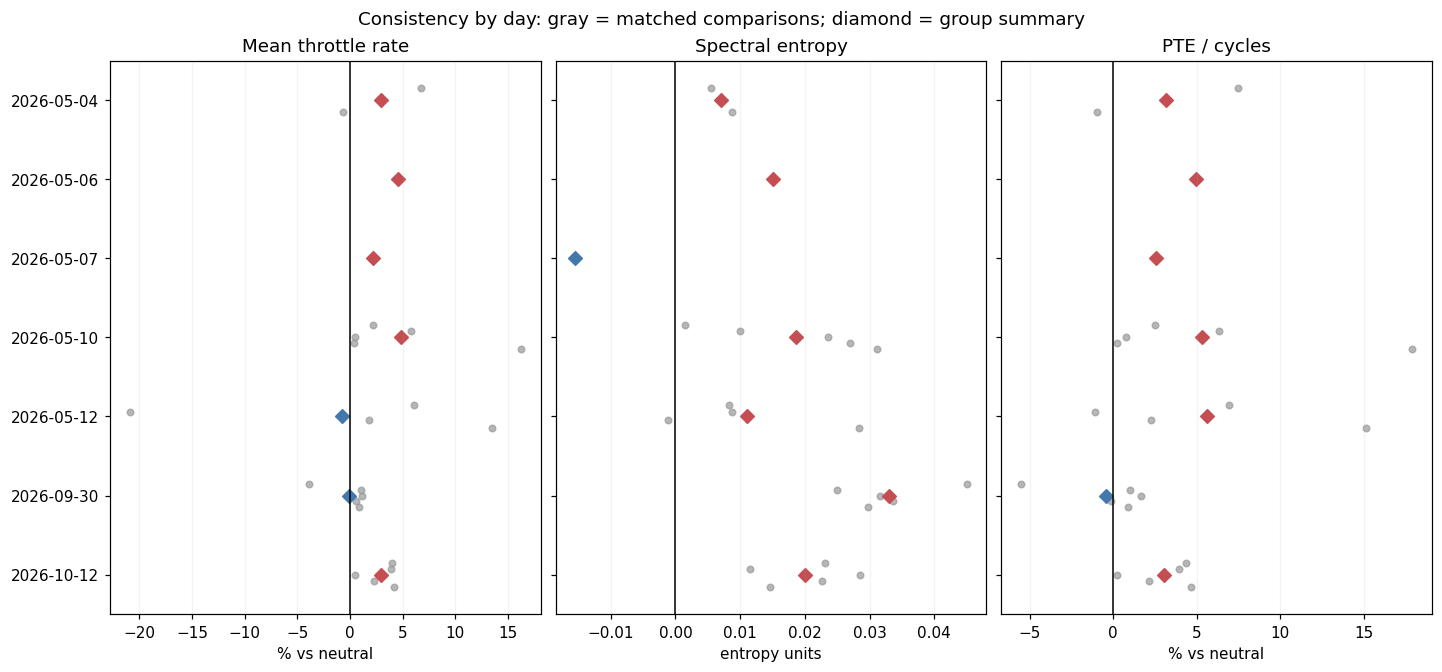

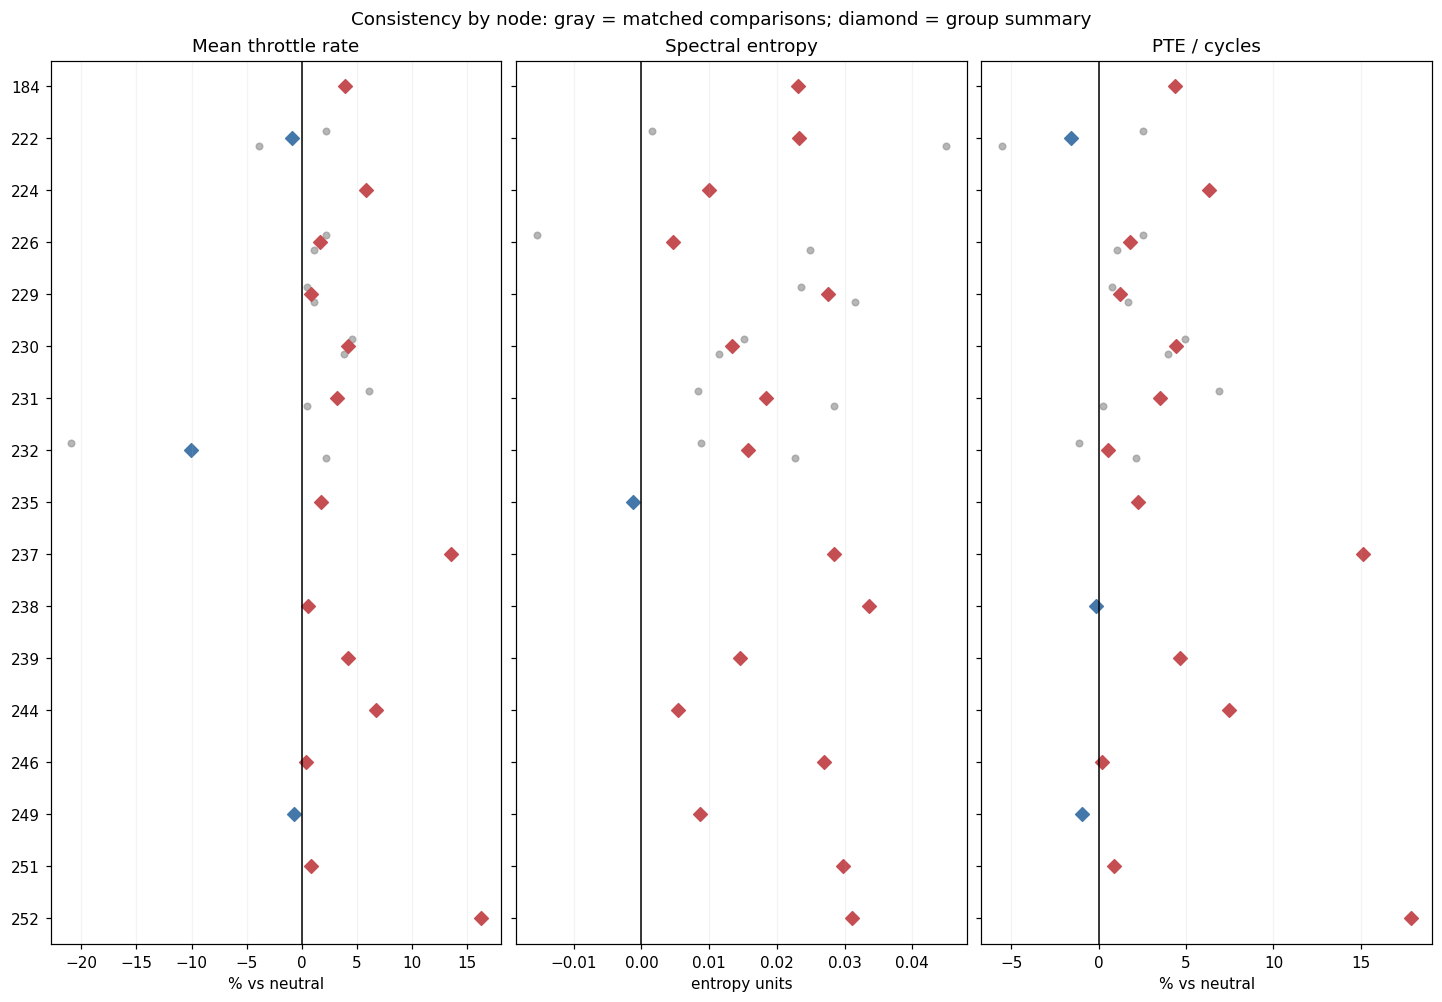

In [6]:
group_summaries = []
for grouping, height in [("day", 6), ("node", 9)]:
    groups = sorted(blocks[grouping].unique(), key=int if grouping == "node" else None)
    fig, axes = plt.subplots(1, len(SPECS), figsize=(13, height), sharey=True, layout="constrained")
    for ax, (feature, label, scale, unit) in zip(axes, SPECS):
        sub = contrasts.loc[contrasts.feature == feature]
        for i, group in enumerate(groups):
            values = sub.loc[sub[grouping] == group]
            summary = float(display_effect(values.contrast.mean(), scale))
            jitter = np.linspace(-.15, .15, len(values)) if len(values) > 1 else [0]
            ax.scatter(values.effect, i + np.asarray(jitter), s=18, color="#999999", alpha=.7)
            ax.scatter(summary, i, marker="D", s=40, color=E_COLOR if summary > 0 else N_COLOR)
            group_summaries.append(dict(grouping=grouping, group=group, feature=feature,
                                        n_blocks=len(values), mean_contrast=values.contrast.mean(),
                                        display_effect=summary,
                                        n_positive=int((values.contrast > 0).sum())))
        ax.axvline(0, color="black", linewidth=1)
        ax.set(title=label, xlabel=unit, yticks=range(len(groups)), yticklabels=groups,
               ylim=(len(groups)-.5, -.5))
        ax.grid(axis="x", alpha=.15)
    fig.suptitle(f"Consistency by {grouping}: gray = matched comparisons; diamond = group summary")
    save_figure(fig, f"consistency_by_{grouping}")
group_summaries = pd.DataFrame(group_summaries)
group_summaries.to_csv(OUT / "descriptive_group_summaries.csv", index=False)

## 5. Could one date or node drive the result?

Remove **one entire date at a time**, refit, and repeat for **one entire node at a time**. Compare the direction and magnitude of the overall estimate with the original.

This is a **sensitivity check**, not held-out prediction or a new family of significance tests. We do not require every smaller dataset to have p < 0.05. A changed sign or large change in magnitude suggests sensitivity; unchanged signs alone do not prove generalization.

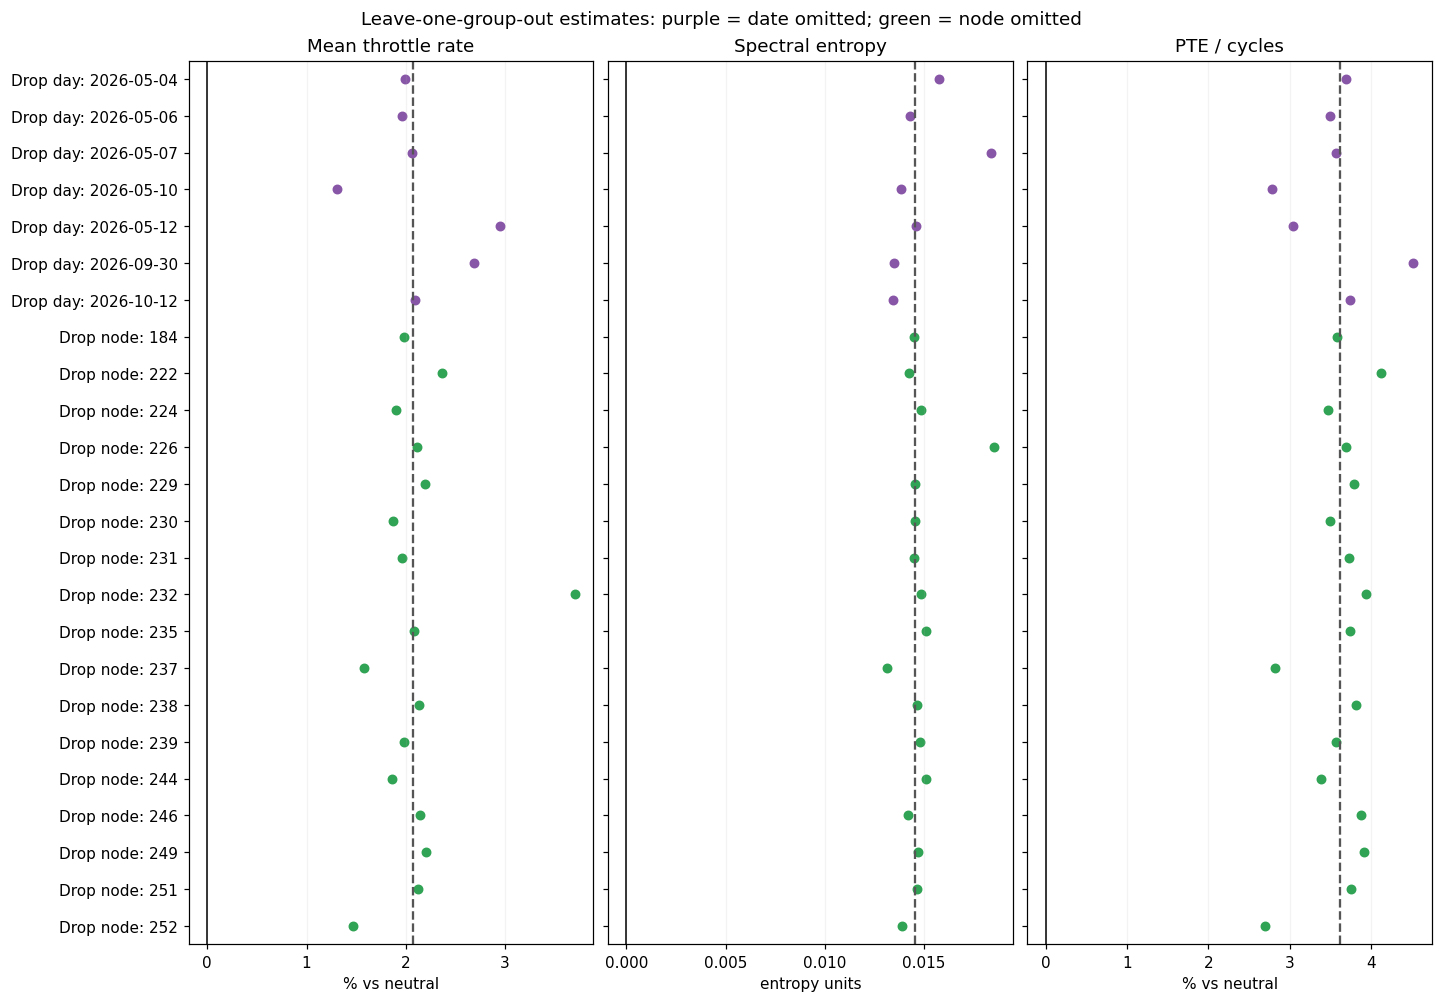

refits  ...  largest_estimate
label              omitted_type          ...                  
Mean throttle rate day                7  ...            2.9499
                   node              17  ...            3.7017
PTE / cycles       day                7  ...            4.5223
                   node              17  ...            4.1213
Spectral entropy   day                7  ...            0.0184
                   node              17  ...            0.0186

[6 rows x 4 columns]

In [7]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 9), sharey=True, layout="constrained")
order = list(sensitivity.loc[sensitivity.feature == FEATURES[0], ["omitted_type", "omitted"]].itertuples(index=False, name=None))
ylabels = [f"Drop {kind}: {name}" for kind, name in order]
for ax, row in zip(axes, estimates.itertuples(index=False)):
    sub = sensitivity.loc[sensitivity.feature == row.feature].set_index(["omitted_type", "omitted"])
    for i, key in enumerate(order):
        ax.scatter(sub.loc[key, "display_estimate"], i,
                   color="#8856A7" if key[0] == "day" else "#31A354", s=30)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(row.display_estimate, color="#555555", linestyle="--", label="Full-data estimate")
    ax.set(title=row.label, xlabel=row.unit, yticks=range(len(order)), yticklabels=ylabels,
           ylim=(len(order)-.5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Leave-one-group-out estimates: purple = date omitted; green = node omitted")
save_figure(fig, "leave_one_group_out")

sensitivity_summary = sensitivity.groupby(["label", "omitted_type"]).agg(
    refits=("same_sign", "size"), same_direction=("same_sign", "sum"),
    smallest_estimate=("display_estimate", "min"), largest_estimate=("display_estimate", "max"))
display(sensitivity_summary.round(4))
sensitivity_summary.to_csv(OUT / "sensitivity_summary.csv")

## 6. Check the model before interpreting its p-values

The first chart estimates how much **variation of matched E−N contrasts** is attributed to node, date, and remaining variation. These are not the earlier raw-measurement variance shares. Zero estimates are allowed; sparse data can also make variance components uncertain.

The Q–Q plots compare covariance-whitened residuals with a normal pattern. Large outliers or strong curves weaken confidence in Gaussian model-based inference. Estimated covariance and the small sample make this a rough diagnostic, not proof of assumptions.

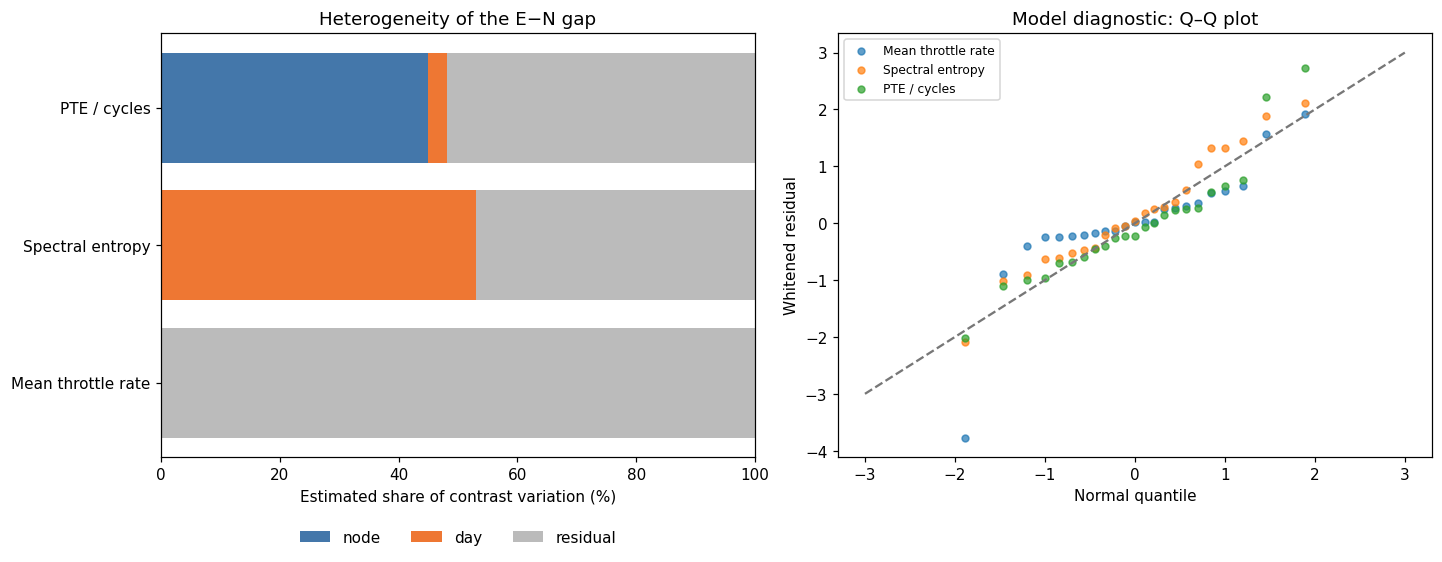

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
left = np.zeros(len(estimates))
for effect, color in [("node", "#4477AA"), ("day", "#EE7733"), ("residual", "#BBBBBB")]:
    values = 100 * estimates[effect + "_fraction"].to_numpy()
    axes[0].barh(range(len(estimates)), values, left=left, color=color, label=effect)
    left += values
axes[0].set(yticks=range(len(estimates)), yticklabels=estimates.label, xlim=(0, 100),
            xlabel="Estimated share of contrast variation (%)", title="Heterogeneity of the E−N gap")
axes[0].legend(loc="upper center", bbox_to_anchor=(.5, -.14), ncol=3, frameon=False)
for feature, label, scale, unit in SPECS:
    values = residuals.loc[residuals.feature == feature, "whitened_residual"]
    theoretical, ordered = stats.probplot(values, fit=False)
    axes[1].scatter(theoretical, ordered, s=20, label=label, alpha=.7)
axes[1].plot([-3, 3], [-3, 3], color="#777777", linestyle="--")
axes[1].set(xlabel="Normal quantile", ylabel="Whitened residual", title="Model diagnostic: Q–Q plot")
axes[1].legend(fontsize=8)
save_figure(fig, "model_diagnostics")

## 7. Read the conclusion feature by feature

- **Average association:** supported only when the Holm-corrected p-value is below 0.05, subject to model assumptions and Monte Carlo precision.
- **Consistency:** inspect the matched differences, group patterns, leave-one-out estimates, and approximate new-group interval. An average association can coexist with reversals.
- **Future generalization:** fresh, independently collected node/date groups provide the strongest check.

Date and batch overlap; condition-specific setup or order differences can remain even after matching. Only six nodes recur on multiple dates, and the overlap graph is sparse/disconnected. The model cannot cleanly distinguish all sources of heterogeneity. Matching controls shared baselines, not every possible confound. No feature below is declared universally stable.

In [9]:
for row in estimates.itertuples(index=False):
    loo = sensitivity.loc[sensitivity.feature == row.feature]
    verdict = "passes the three-feature correction" if row.supported else "does not pass the three-feature correction"
    prediction_note = "includes both directions" if row.prediction_crosses_zero else "keeps one direction under the model"
    display(Markdown(
        f"**{row.label}:** average E−N = **{row.display_estimate:+.3g} {row.unit}** "
        f"(pointwise 95% CI {row.display_ci_low:+.3g} to {row.display_ci_high:+.3g}); "
        f"Holm p = **{row.p_holm:.3g}**, {verdict}. "
        f"E is numerically higher in **{row.n_positive}/{len(blocks)}** matched groups. "
        f"**{int(loo.same_sign.sum())}/{len(loo)}** omission estimates keep the full-data direction. "
        f"The approximate new-group interval **{prediction_note}**."
        + (" **Simulation precision could change the corrected decision.**" if row.mc_sensitive else "")))

for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("Verified: input metadata and feature files are unchanged.")
print(f"Tables, figures, and configuration: {OUT.relative_to(ROOT)}")

**Mean throttle rate:** average E−N = **+2.07 % vs neutral** (pointwise 95% CI -0.721 to +4.89); Holm p = **0.131**, does not pass the three-feature correction. E is numerically higher in **20/23** matched groups. **24/24** omission estimates keep the full-data direction. The approximate new-group interval **includes both directions**.

**Spectral entropy:** average E−N = **+0.0146 entropy units** (pointwise 95% CI +0.00249 to +0.0273); Holm p = **0.0866**, does not pass the three-feature correction. E is numerically higher in **21/23** matched groups. **24/24** omission estimates keep the full-data direction. The approximate new-group interval **includes both directions**.

**PTE / cycles:** average E−N = **+3.62 % vs neutral** (pointwise 95% CI +1.01 to +6.2); Holm p = **0.0382**, passes the three-feature correction. E is numerically higher in **19/23** matched groups. **24/24** omission estimates keep the full-data direction. The approximate new-group interval **includes both directions**.

Verified: input metadata and feature files are unchanged.
Tables, figures, and configuration: results/fulltrace_matched_EN_2026-10-23_three_features
